In [53]:
import numpy as np
import pandas as pd
from IPython.display import display
from pathlib import Path
import matplotlib.pyplot as plt

In [2]:
data_path = Path("../data/processed")

csv_files = list(data_path.glob("*.csv"))

display(csv_files[0].name)

def read_datasets(datasets):
    dataframe = {}
    for dataset in datasets:
        filename = dataset.name
        dataframe[filename] = pd.read_csv(dataset)
    return dataframe

def convert_to_datetime(dataset, columns):
    for column in columns:
        dataset[column] = pd.to_datetime(dataset[column])
    return dataset

orders_dataset_columns_to_datetime = [
    "order_purchase_timestamp", 
    "order_approved_at", 
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date" 
    ]

order_items_dataset_columns_to_datetime = [
    "shipping_limit_date" 
    ]

order_reviews_dataset_columns_to_datetime = [
    "review_creation_date",
    "review_answer_timestamp" 
    ]

datasets = read_datasets(csv_files)

customers_dataset = datasets["olist_customers_dataset.csv"]
geolocation_dataset = datasets["olist_geolocation_dataset.csv"]
order_payments_dataset = datasets["olist_order_payments_dataset.csv"]
products_dataset = datasets["olist_products_dataset.csv"]
sellers_dataset = datasets["olist_sellers_dataset.csv"]
category_translation_dataset = datasets["product_category_name_translation.csv"]

orders_dataset = convert_to_datetime(dataset=datasets["olist_orders_dataset.csv"], columns=orders_dataset_columns_to_datetime)
orders_items_dataset = convert_to_datetime(dataset=datasets["olist_order_items_dataset.csv"], columns=order_items_dataset_columns_to_datetime)
reviews_dataset = convert_to_datetime(dataset=datasets["olist_order_reviews_dataset.csv"], columns=order_reviews_dataset_columns_to_datetime)

display(orders_dataset.dtypes)
display(orders_items_dataset.dtypes)
display(reviews_dataset.dtypes)

'olist_customers_dataset.csv'

order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

order_id                          str
order_item_id                   int64
product_id                        str
seller_id                         str
shipping_limit_date    datetime64[us]
price                         float64
freight_value                 float64
dtype: object

review_id                             str
order_id                              str
review_score                        int64
review_comment_title                  str
review_comment_message                str
review_creation_date       datetime64[us]
review_answer_timestamp    datetime64[us]
dtype: object

In [3]:
#How many customers?
display(customers_dataset.head(1))
unique_customers = customers_dataset["customer_unique_id"].nunique()
all_customers = customers_dataset["customer_id"].count()
display(f"Total number of unique customers: {unique_customers}")
display(f"Total number of customers: {all_customers}")

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP


'Total number of unique customers: 96096'

'Total number of customers: 99441'

In [4]:
#How many sellers?
display(sellers_dataset.head(1))
display(len(sellers_dataset["seller_id"]))

number_of_sellers = sellers_dataset["seller_id"].nunique()
display(f"Total number of sellers: {number_of_sellers}")

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP


3095

'Total number of sellers: 3095'

In [5]:
#How many products?
display(products_dataset.head(1))
display(len(products_dataset["product_id"]))

number_of_unique_products = products_dataset["product_id"].nunique()
display(f"Total number of unique products: {number_of_unique_products}")

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0


32951

'Total number of unique products: 32951'

In [6]:
#How many orders?
orders_dataset.head(1)
display(len(orders_dataset["order_id"]))

number_of_orders = orders_dataset["order_id"].nunique()
display(f"Total number of orders: {number_of_orders}")

99441

'Total number of orders: 99441'

In [7]:
#How many reviews?
reviews_dataset.head(1)

display(f"Total number of review_id: {len(reviews_dataset["review_id"])}")

number_of_reviews = reviews_dataset["review_id"].nunique()
display(f"Total number of reviews (unique): {number_of_reviews}")

'Total number of review_id: 99224'

'Total number of reviews (unique): 98410'

In [8]:
orders_dataset["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [9]:
#What proportion of orders are delivered?
def orders_status_percentage(dataset, order_status):
    orders_with_status = dataset[dataset["order_status"] == order_status]
    percentage_of_orders = round((len(orders_with_status) / len(dataset)) * 100, 3)
    return f"Percentage of {order_status} orders is {percentage_of_orders}%"

delivered_orders = display(orders_status_percentage(dataset=orders_dataset, order_status="delivered"))
#What proportion of orders are cancelled?
canceled_orders = display(orders_status_percentage(dataset=orders_dataset, order_status="canceled"))
unavailable_orders = display(orders_status_percentage(dataset=orders_dataset, order_status="unavailable"))

'Percentage of delivered orders is 97.02%'

'Percentage of canceled orders is 0.629%'

'Percentage of unavailable orders is 0.612%'

,Year,Orders,Growth (%)
0,2016,329,NaN
1,2017,45101,13608.51
2,2018,54011,19.76


,Month,Sales 2016,Sales 2017,Sales 2018
0,January,0,800,7269
1,February,0,1780,6728
2,March,0,2682,7211
3,April,0,2404,6939
4,May,0,3700,6873
5,June,0,3245,6167
6,July,0,4026,6292
7,August,0,4331,6512
8,September,4,4285,16
9,October,324,4631,4


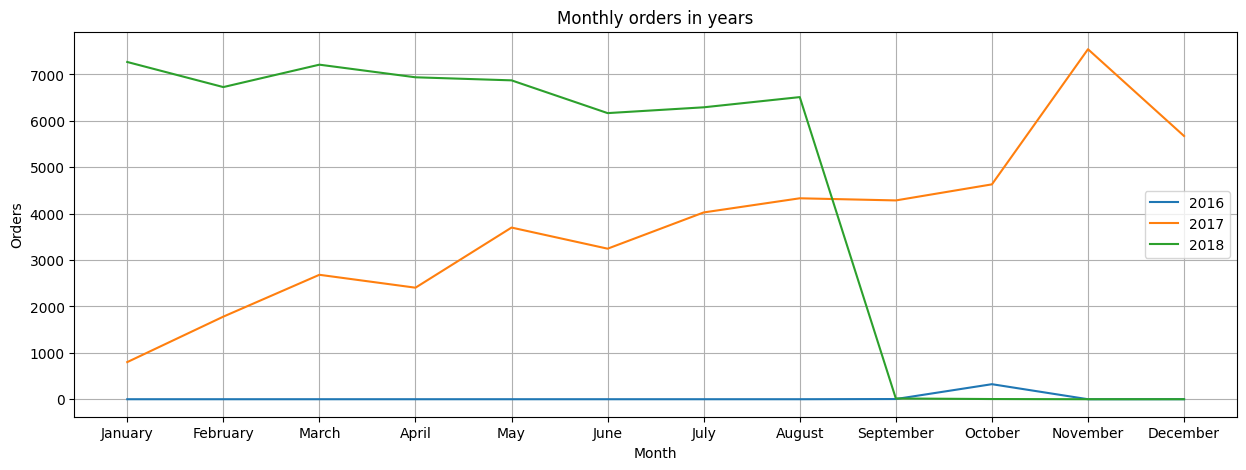

In [58]:
#Is the platform growing?
#Are orders increasing or decreasing?
orders_dataset.head()
orders_dataset.dtypes
orders_purchased_2016 = orders_dataset["order_purchase_timestamp"].dt.year == 2016
orders_purchased_2017 = orders_dataset["order_purchase_timestamp"].dt.year == 2017
orders_purchased_2018 = orders_dataset["order_purchase_timestamp"].dt.year == 2018


yearly_sales = pd.DataFrame(
    {
        "Year": [2016, 2017, 2018],
        "Orders": [
          orders_purchased_2016.sum(),
          orders_purchased_2017.sum(),
          orders_purchased_2018.sum()  
        ]
    }
)

yearly_sales["Growth (%)"] = round(yearly_sales["Orders"].pct_change() * 100, 2)


display(yearly_sales) #Based on this it can be seen that the platform definietely growing 

#Are there seasonal patterns?
#Which months are strongest?
def calculate_monthly_sale(dataset, year):
    monthly_sales = {}
    year_sales = dataset[dataset["order_purchase_timestamp"].dt.year == year]
    for month in range(1, 13):
        monthly_sales[month] = (year_sales["order_purchase_timestamp"].dt.month == month).sum()
    return monthly_sales

monthly_sales_2016 = calculate_monthly_sale(dataset=orders_dataset, year=2016)
monthly_sales_2017 = calculate_monthly_sale(dataset=orders_dataset, year=2017)
monthly_sales_2018 = calculate_monthly_sale(dataset=orders_dataset, year=2018)

pd_monthly_sales = pd.DataFrame(
    {
    "Month": ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"],
    "Sales 2016": monthly_sales_2016.values(),
    "Sales 2017": monthly_sales_2017.values(),
    "Sales 2018": monthly_sales_2018.values()
    }
)

display(pd_monthly_sales)

plt.figure(figsize=(15, 5))

plt.plot(
    pd_monthly_sales["Month"],
    pd_monthly_sales["Sales 2016"],
    label = 2016
)

plt.plot(
    pd_monthly_sales["Month"],
    pd_monthly_sales["Sales 2017"],
    label = 2017
)

plt.plot(
    pd_monthly_sales["Month"],
    pd_monthly_sales["Sales 2018"],
    label = 2018
)

plt.title("Monthly orders in years")
plt.xlabel("Month")
plt.ylabel("Orders")
plt.legend()
plt.grid()

plt.show()



Customers Analysis

In [ ]:
#Where are customers located?
#Which states have the most customers?
#How many customers make repeat purchases?
#Are most customers one-time buyers?

#Where are customers located?
display(customers_dataset.head())



,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP
